<a href="https://colab.research.google.com/github/Venegast/Curso-Econometria/blob/main/Tarea_HW01MFWK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Caso de Estudio: Parque Fotovoltaico "Atacama Sun"**
**Empresa:** Andes Renewable Energy S.A.

**Ubicación:** Región de Atacama, Chile

### **Datos del Proyecto**

- **Inversión inicial ($I_0$):** US\$100 millones para una planta fotovoltaica de 120 MW.

- **Tasa de descuento ( r ):** 8%

- **Tasa de crecimiento de flujos ( g ):** 2% anual

- **Flujo de caja libre esperado del año 1 ( FCF1 ):** El modelo del departamento de ingeniería proyecta un flujo neto de US\$7 millones en el primer año.

La fórmula simplificada de *Valor Actual Neto (VAN)* a perpetuidad es:

$$VAN = -I_0 + \frac{FCF_1}{r - g}$$



En la evaluación de proyectos de infraestructura y energía, basarse exclusivamente en un "escenario promedio" genera una falsa sensación de seguridad. El verdadero riesgo de un proyecto no está en su valor esperado, sino en la variabilidad de sus resultados y en su exposición a eventos de cola (escenarios adversos de baja probabilidad pero alto impacto). Para modelar esta incertidumbre, se construyó una simulación de Monte Carlo asumiendo que el *flujo de caja libre del año 1 ($FCF_1$)* sigue una Distribución Normal con media $\mu = \$7.0\text{M}$ y desviación estándar $\sigma = \$1.5\text{M}$.


## **Código Base**

In [ ]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# REEMPLAZA ESTA SEMILLA PARA REPRODUCIBILIDAD
np.random.seed(8941)    # Usa los 4 últimos dígitos de tu Rut sin el dígito verificador

In [ ]:
# PARÁMETROS
n_sims = 10000             # Número de simulaciones
inversion_inicial = 100.0  # Inversión en planta 120 MW en el Norte de Chile
r = 0.08                   # Tasa de descuento
g = 0.02                   # Tasa de crecimiento de flujo de caja

In [ ]:
# 1. SIMULACIÓN BASE
np.random.seed(8941)    # Usa los 4 últimos dígitos de tu Rut sin el dígito verificador
fcf_1 = np.random.normal(loc=7.0, scale=1.5, size=n_sims)  # Flujo de caja libre con media = US$7.0M y desviación estándar = US$1.5M

# 2. CÁLCULO DEL VALOR ACTUAL NETO (VAN)
van_simulados = -inversion_inicial + (fcf_1 / (r - g))

# 3. MÉTRICAS CLAVE
media = np.mean(van_simulados)
mediana = np.median(van_simulados)
p5 = np.percentile(van_simulados, 5)     # VaR 5% (Peor 5% de los casos)
p95 = np.percentile(van_simulados, 95)   # Escenario Optimista
desv_est = np.std(van_simulados, ddof=1) # Desviación estándar
prob_perder = np.mean(van_simulados < 0) * 100

print(f"--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE NORMAL) ---")
print(f"VAN Medio: ${media:.2f}M USD")
print(f"VAN Mediano: ${mediana:.2f}M USD")
print(f"Percentil 5 (P5 / VaR 5%): ${p5:.2f}M USD")
print(f"Percentil 95 (P95): ${p95:.2f}M USD")
print(f"VAN Desviación estándar: ${desv_est:.2f}M USD")
print(f"Probabilidad de Destruir Valor (VPN < 0): {prob_perder:.1f}%")

--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE NORMAL) ---
VAN Medio: $16.56M USD
VAN Mediano: $16.31M USD
Percentil 5 (P5 / VaR 5%): $-23.95M USD
Percentil 95 (P95): $58.43M USD
VAN Desviación estándar: $25.20M USD
Probabilidad de Destruir Valor (VPN < 0): 25.4%


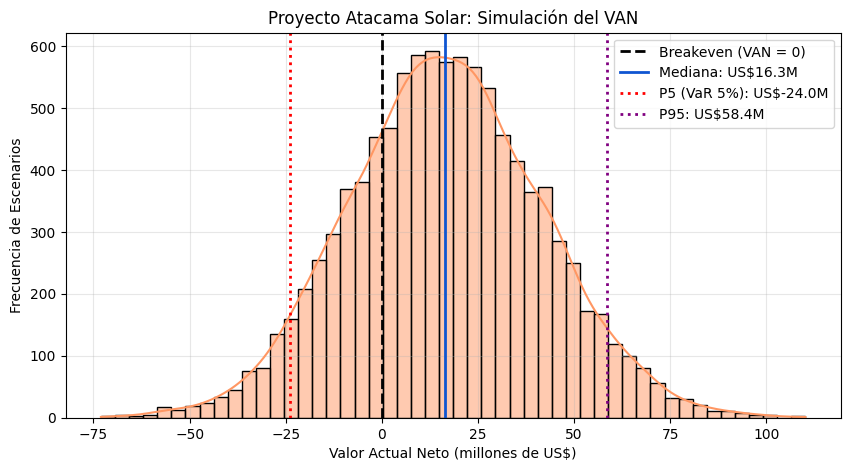

In [ ]:
# 4. VISUALIZACIÓN DE RESULTADOS
plt.figure(figsize=(10, 5))
sns.histplot(van_simulados, kde=True, bins=50, color='#FF9763')

# Líneas de referencia
plt.axvline(0, color='black', linestyle='--', linewidth=2, label='Breakeven (VAN = 0)')
plt.axvline(mediana, color='#0F55D1', linestyle='-', linewidth=2, label=f'Mediana: US${mediana:.1f}M')
plt.axvline(p5, color='red', linestyle=':', linewidth=2, label=f'P5 (VaR 5%): US${p5:.1f}M')
plt.axvline(p95, color='purple', linestyle=':', linewidth=2, label=f'P95: US${p95:.1f}M')

plt.title('Proyecto Atacama Solar: Simulación del VAN')
plt.xlabel('Valor Actual Neto (millones de US$)')
plt.ylabel('Frecuencia de Escenarios')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Antes de responder las preguntas 2 a 7, cambia la semilla usando los 4 últimos dígitos de tu Rut sin el dígito verificador:**

## **Pregunta 1**

Utilizando la propiedad de linealidad del valor esperado $E[a + bX] = a + bE[X]$, calcula el valor esperado del VAN, asumiendo que el $FCF_1 \sim N(\mu=7.0, \sigma=1.5)$. Compara este valor promedio del VAN obtenido en la simulación.

**Solución:**

$E(VAN)=-I_0+\frac{E(FC_1)}{r-g}=-100+\frac{7}{0.08-0.02}=-100+116.67=\text{US\$16.67 millones}$

El valor promedio VAN obtenido a través de la simulación es 16.39 millones de dólares, por lo que hay una pequeña diferencia debido a la variabilidad muestral del generador pseudoaleatorio.

## **Pregunta 2**

Aplicando la propiedad de la varianza para transformaciones lineales $Var(a + bX) = b^2 Var(X)$, determina analíticamente la varianza y la desviación estándar del VAN, asumiendo que el  $FCF_1 \sim N(\mu=7.0, \sigma=1.5)$. Compara la desviación estándar con la obtenida en las simulaciones (5 puntos)

Var (VAN) = b^2Var(X);

Var (VAN) =((1)/(0,08-0,02))^2 * (1,5)^2

Var (VAN) = USD$625 millones,



Desv.Estnd (VAN) = USD$25 millones

## **Pregunta 3**

A partir de la Media ($\mu_{VAN}$) y la Desviación Estándar ($\sigma_{VAN}$) teóricas obtenidas en las *preguntas 1 y 2*. Calcula con Python la probabilidad teórica exacta de que el proyecto destruya valor ($VAN < 0$). Compara este valor con el obtenido a través de las simulaciones. Escribe la función de Python utilizada en el siguiente espacio (10 puntos)

Calculo Probabilidad VAN < 0

Z = (X - μ)/σ;
Donde;
X = FCF1 --> US$ 6 millones

In [ ]:
Z = ((6 - 7) / 1.5 )
print(f"Valor Z: {Z:.2f}%")


Valor Z: -0.67%


In [ ]:
# Codigo Python // Calculo del VAN < 0

VAN_menor_0 = np.mean(van_simulados < 0) * 100
print(f"Prob_VAN < 0 (VPN < 0): {VAN_menor_0:.1f}%")


Prob_VAN < 0 (VPN < 0): 25.4%


In [ ]:
# Comparacion VAN < 0
print ("Comparacion VAN < 0")

print(f"Probabilidad de Destruir Valor (VPN < 0): {prob_perder:.1f}%")
print(f"Prob_VAN_menor_0 (VPN < 0): {VAN_menor_0:.1f}%")
print ("Ambas Simulaciones entregan el mismo resultado valor")


Comparacion VAN < 0
Probabilidad de Destruir Valor (VPN < 0): 25.4%
Prob_VAN_menor_0 (VPN < 0): 25.4%
Ambas Simulaciones entregan el mismo resultado valor


## **Pregunta 4**

En el contexto del mercado eléctrico chileno (congestión en transmisión, precios marginales cero a determinadas horas y curtailment), ¿cuáles son las principales deficiencias de asumir que el flujo de caja ($FCF_1$) tenga una *distribución normal*? Argumenta tu respuesta desde el punto de vista financiero y operativo en un máximo de 10 líneas (10 puntos)

**RESPUESTA:**

Estariamos asumiendo que los ingresos no estarian siendo afectados por escenarios que estan posicionados en la cola de la distribucion a pesar de tener una baja probabilidad, subestimado impactos en la liquidez.

En situaciones donde los precios tieneden a ser cero (principalmente en horarios donde hay mayor generacion de energia renovable), no poder aportar a la red dado que la carretera electrica se encuentra saturada, debido aun desequilibrio entre oferta y demanda y tener que "botar" energia. Afectan de manera importante Flujo de caja.










## **Pregunta 5**

Simula el $FCF_1$ utilizando una *distribución log-normal* que mantenga la media objetivo ($\mu$) en US\$ 7 millones y la desviación estándar ($\sigma$) en US\$ 1.5 millones.  Para trabajar con la función `np.random.lognormal(mean, sigma, size)` en Python debes transformar la media y la desviación estándar del espacio lineal al espacio logarítmico ($\mu_{log}$ y $\sigma_{log}$) mediante las siguientes fórmulas:

$$\sigma_{log} = \sqrt{\ln\left(1 + \left(\frac{\sigma}{\mu}\right)^2\right)}$$

$$\mu_{log} = \ln(\mu) - \frac{\sigma_{log}^2}{2}$$



(a) ¿Cuál es el Value at Risk al 5% ($VaR_{5\%}$ / Percentil 5) y la probabilidad de pérdida ($VAN < 0$) bajo la distribución log-normal? Compáralos con los resultados del modelo Normal de la simulación base (Especifica los valores de $\sigma_{log}$ y $\mu_{log}$ y la(s) línea(s) de código que cambiaste en tu respuesta) (10 puntos).

In [ ]:
np.random.seed(8941)    # Usa los 4 últimos dígitos de tu Rut sin el dígito verificador
mu = 7.0
sigma = 1.5

sigma_log = np.sqrt(np.log(1 + (sigma/mu)**2))
mu_log = np.log(mu) - (sigma_log**2) / 2

fcf_2 = np.random.lognormal(mean=mu_log, sigma=sigma_log, size=n_sims)

van_simulados_2 = -inversion_inicial + (fcf_2 / (r - g))

# 3. MÉTRICAS CLAVE LOG NORMAL
media_2 = np.mean(van_simulados_2)
mediana_2 = np.median(van_simulados_2)
p5_2 = np.percentile(van_simulados_2, 5)     # VaR 5% (Peor 5% de los casos)
p95_2 = np.percentile(van_simulados_2, 95)   # Escenario Optimista
desv_est_2 = np.std(van_simulados_2, ddof=1) # Desviación estándar
prob_perder_2 = np.mean(van_simulados_2 < 0) * 100

print(f"σlog (Desviación estándar logarítmica): {sigma_log:.2f}")
print(f"μlog (Media logarítmica): {mu_log:.2f}")
print("----------------------------------------------------")
print(f"--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE NORMAL) ---")
print(f"VAN Medio: ${media:.2f}M USD")
print(f"VAN Mediano: ${mediana:.2f}M USD")
print(f"Percentil 5 (P5 / VaR 5%): ${p5:.2f}M USD")
print(f"Percentil 95 (P95): ${p95:.2f}M USD")
print(f"VAN Desviación estándar: ${desv_est:.2f}M USD")
print(f"Probabilidad de Destruir Valor (VPN < 0): {prob_perder:.2f}%")
print("----------------------------------------------------")
print(f"--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE LOGNORMAL) ---")
print(f"VAN Medio_2: ${media_2:.2f}M USD")
print(f"VAN Mediano_2: ${mediana_2:.2f}M USD")
print(f"Percentil 5_2 (P5 / VaR 5%): ${p5_2:.2f}M USD")
print(f"Percentil 95_2 (P95): ${p95_2:.2f}M USD")
print(f"VAN Desviación estándar_2: ${desv_est_2:.2f}M USD")
print(f"Probabilidad de Destruir Valor_2 (VPN < 0): {prob_perder_2:.2f}%")

σlog (Desviación estándar logarítmica): 0.21
μlog (Media logarítmica): 1.92
----------------------------------------------------
--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE NORMAL) ---
VAN Medio: $16.56M USD
VAN Mediano: $16.31M USD
Percentil 5 (P5 / VaR 5%): $-23.95M USD
Percentil 95 (P95): $58.43M USD
VAN Desviación estándar: $25.20M USD
Probabilidad de Destruir Valor (VPN < 0): 25.42%
----------------------------------------------------
--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE LOGNORMAL) ---
VAN Medio_2: $16.61M USD
VAN Mediano_2: $13.73M USD
Percentil 5_2 (P5 / VaR 5%): $-19.15M USD
Percentil 95_2 (P95): $62.53M USD
VAN Desviación estándar_2: $25.32M USD
Probabilidad de Destruir Valor_2 (VPN < 0): 26.97%


**Respuesta (a)**

VaR5%_LogNormal : US$-19,15M  
VAN_LogNormal < 0: 26,97%

σlog (Desviación estándar logarítmica): 0.21  
μlog (Media logarítmica): 1.92



(b) Si la política de riesgos de la empresa establece un límite de tolerancia donde el $VaR_{5\%}$ no puede superar las pérdidas de $US\$ 30.0$ millones, ¿se aprueba o se rechaza el proyecto bajo este modelo de colas pesadas? Justifica en un máximo de 5 líneas (10 puntos)


**Respuesta (b)**
|  
Se aprueba el Proyeto, VaR5% < US-30.0 millones

## **Pregunta 6**

Para mitigar el riesgo de vertimiento de energía durante las horas solares, el equipo de ingeniería propone instalar un sistema de baterías de almacenamiento (BESS). Esta tecnología requiere aumentar la inversión inicial en US\$ 15 millones ($I_0 = \text{US\$ 115 millones}$), pero cambia drásticamente la distribución del flujo de caja del primer año ($FCF_1$) al garantizar un piso de generación. El equipo de operaciones define la nueva incertidumbre del $FCF_1$ mediante una *distribución triangular* con los siguientes tres parámetros:

- **Mínimo ($a$):** US$ 5.0 millones (piso garantizado por la capacidad de descarga de la batería en horas punta).  

- **Moda ($c$):** US$ 7.5 millones (Incremento en ventas al desplazar energía de costo cero a horas de mayor precio).  

- **Máximo ($b$):** US$ 10.0 millones (Capacidad máxima de captura y venta de energía del sistema).

(a) Simula el $FCF_1$ con la distribución triangular `np.random.triangular(left=5, mode=7.5, right=11, size=10000)`. Calcula el $VaR_{5\%}$ (Percentil 5) y la $Prob(VAN<0)$, considerando la nueva inversión inicial de US$ 115 millones (10 puntos)

**Respuesta (a)**

In [ ]:
np.random.seed(8941)    # Usa los 4 últimos dígitos de tu Rut sin el dígito verificador

# PARÁMETROS
size = 10000             # Número de simulaciones
inversion_inicial_2 = 115.0  # Inversión en planta 120 MW en el Norte de Chile
a = 5
c = 7.5
b = 10
Fcf_3 = np.random.triangular(left= a, mode=c, right=b, size=10000)
van_simulados_3 = -inversion_inicial_2 + (Fcf_3 / (r - g))

# 3. MÉTRICAS CLAVE DISTR.TRIANGULAR
media_3 = np.mean(van_simulados_3)
mediana_3 = np.median(van_simulados_3)
p5_3 = np.percentile(van_simulados_3, 5)     # VaR 5% (Peor 5% de los casos)
p95_3 = np.percentile(van_simulados_3, 95)   # Escenario Optimista
desv_est_3 = np.std(van_simulados_3, ddof=1) # Desviación estándar
prob_perder_3 = np.mean(van_simulados_3 < 0) * 100

print(f"--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE LOGNORMAL) ---")
print(f"VAN Medio_2: ${media_2:.2f}M USD")
print(f"VAN Mediano_2: ${mediana_2:.2f}M USD")
print(f"Percentil 5_2 (P5 / VaR 5%): ${p5_2:.2f}M USD")
print(f"Percentil 95_2 (P95): ${p95_2:.2f}M USD")
print(f"VAN Desviación estándar_2: ${desv_est_2:.2f}M USD")
print(f"Probabilidad de Destruir Valor_2 (VPN < 0): {prob_perder_2:.2f}%")
print("----------------------------------------------------")
print(f"--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE Triangular) ---")
print(f"VAN Medio_3: ${media_3:.2f}M USD")
print(f"VAN Mediano_3: ${mediana_3:.2f}M USD")
print(f"Percentil 5_3 (P5 / VaR 5%): ${p5_3:.2f}M USD")
print(f"Percentil 95_3 (P95): ${p95_3:.2f}M USD")
print(f"VAN Desviación estándar_3: ${desv_est_3:.2f}M USD")
print(f"Probabilidad de Destruir Valor_3 (VPN < 0): {prob_perder_3:.2f}%")

--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE LOGNORMAL) ---
VAN Medio_2: $16.61M USD
VAN Mediano_2: $13.73M USD
Percentil 5_2 (P5 / VaR 5%): $-19.15M USD
Percentil 95_2 (P95): $62.53M USD
VAN Desviación estándar_2: $25.32M USD
Probabilidad de Destruir Valor_2 (VPN < 0): 26.97%
----------------------------------------------------
--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE Triangular) ---
VAN Medio_3: $9.71M USD
VAN Mediano_3: $9.75M USD
Percentil 5_3 (P5 / VaR 5%): $-18.77M USD
Percentil 95_3 (P95): $38.98M USD
VAN Desviación estándar_3: $17.12M USD
Probabilidad de Destruir Valor_3 (VPN < 0): 29.64%


(b) Compara estos resultados con la situación sin baterías usando la distribución log-normal *(Pregunta 5)*. ¿Qué decisión recomiendas tomar? Evalúa en tu respuesta la compensación entre una mayor inversión inicial y la mejora en la certeza operativa del proyecto (10 puntos)

 **B.1
Comparacion resultados Distrb Log Normal vs Triangular**

--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE LOGNORMAL) ---

VAN Medio_2: $16.61M USD

VAN Mediano_2: $13.73M USD

Percentil 5_2 (P5 / VaR 5%): $-19.15M USD

Percentil 95_2 (P95): $62.53M USD

VAN Desviación estándar_2: $25.32M USD

Probabilidad de Destruir Valor_2 (VPN < 0): 26.97%

----------------------------------------------------
--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE Triangular) ---
VAN Medio_3: $9.71M USD

VAN Mediano_3: $9.75M USD

Percentil 5_3 (P5 / VaR 5%): $-18.77M USD

Percentil 95_3 (P95): $38.98M USD

VAN Desviación estándar_3: $17.12M USD

Probabilidad de Destruir Valor_3 (VPN < 0): 29.64%


 **B.2
Recomendación**

En base a los resultados obtenidos y comparacion entre ambas simulaciones, se recomienda tomar la desicion de no inluir la inversion de baterias de almacenamiento.

Si bien, con la incorporacion de baterias logra estabilizar los flujos reduciendo en US$8,2 millones.  la inversion genera un fuerte impacto en el VAN Medio, reduciendolo un 42,8%.

Por otro lado la Probalidad de VAN < 0 Crece en 267 puntos base.
finalmente en la simulacion sin bateria el P95 crece en un 60% vs el P5 que solo presenta una Var de 2%.


## **Pregunta 7**

Asume que el horizonte de evaluación corresponde a la vida útil operativa de los activos, $T=30$, y utiliza la fórmula para una anualidad creciente:

$$VAN=-I_0+\frac{FCF_1}{r-g}\times \left[1-\left(\frac{1+g}{1+r}\right)^T\right]$$


(a) Bajo el supuesto del modelo que asume que $I_0=100$ y $FCF_1 \sim N(\mu=7, \sigma=1.5)$), calcula la nueva media ($\mu_{VAN, 30}$) y desviación estándar ($\sigma_{VAN, 30}$) para $T=30$ (10 puntos)  

**Respuesta (a)**

In [ ]:
np.random.seed(8941)    # Usa los 4 últimos dígitos de tu Rut sin el dígito verificador

fcf_1 = np.random.normal(loc=7.0, scale=1.5, size=n_sims)  # Flujo de caja libre con media = US$7.0M y desviación estándar = US$1.5M

inversion_inicial_4 = 100.0 # Inversión en planta 120 MW en el Norte de Chile
t=30                        # Vida Util Operativa
r = 0.08                    # Tasa de descuento
g = 0.02                    # Tasa de crecimiento de flujo de caja


# 2. CÁLCULO DEL VALOR ACTUAL NETO (VAN)
van_simulados_4 = -inversion_inicial_4 + (fcf_1 / (r - g))*(1- ((1 + g)/(1 + r))**t)

# 3. MÉTRICAS CLAVE Perpetua
media = np.mean(van_simulados)
mediana = np.median(van_simulados)
p5 = np.percentile(van_simulados, 5)     # VaR 5% (Peor 5% de los casos)
p95 = np.percentile(van_simulados, 95)   # Escenario Optimista
desv_est = np.std(van_simulados, ddof=1) # Desviación estándar
prob_perder = np.mean(van_simulados < 0) * 100

print(f"--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE NORMAL PERPETUA) ---")
print(f"VAN Medio_P: ${media:.2f}M USD")
print(f"VAN Mediano_P: ${mediana:.2f}M USD")
print(f"Percentil_P 5 (P5 / VaR 5%): ${p5:.2f}M USD")
print(f"Percentil_P 95 (P95): ${p95:.2f}M USD")
print(f"VAN Desviación estándar_P: ${desv_est:.2f}M USD")
print(f"Probabilidad de Destruir Valor_P (VPN < 0): {prob_perder:.1f}%")
print("----------------------------------------------------")

# 4. MÉTRICAS CLAVE t = 30
media = np.mean(van_simulados_4)
mediana = np.median(van_simulados_4)
p5= np.percentile(van_simulados_4, 5)     # VaR 5% (Peor 5% de los casos)
p95 = np.percentile(van_simulados_4, 95)   # Escenario Optimista
desv_est = np.std(van_simulados_4, ddof=1) # Desviación estándar
prob_perder = np.mean(van_simulados_4 < 0) * 100

print(f"--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE NORMAL t=30) ---")
print(f"VAN Medio_t30: ${media:.2f}M USD")
print(f"VAN Mediano_t30: ${mediana:.2f}M USD")
print(f"Percentil_t30 50 (P5 / VaR 5%): ${p5:.2f}M USD")
print(f"Percentil_t30 95 (P95): ${p95:.2f}M USD")
print(f"VAN Desviación estándar_t30: ${desv_est:.2f}M USD")
print(f"Probabilidad VAN_t30 (VPN < 0): {prob_perder:.1f}%")



--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE NORMAL PERPETUA) ---
VAN Medio_P: $16.56M USD
VAN Mediano_P: $16.31M USD
Percentil_P 5 (P5 / VaR 5%): $-23.95M USD
Percentil_P 95 (P95): $58.43M USD
VAN Desviación estándar_P: $25.20M USD
Probabilidad de Destruir Valor_P (VPN < 0): 25.4%
----------------------------------------------------
--- PROYECTO SOLAR ATACAMA (SIMULACIÓN BASE NORMAL t=30) ---
VAN Medio_t30: $-4.42M USD
VAN Mediano_t30: $-4.63M USD
Percentil_t30 50 (P5 / VaR 5%): $-37.64M USD
Percentil_t30 95 (P95): $29.92M USD
VAN Desviación estándar_t30: $20.66M USD
Probabilidad VAN_t30 (VPN < 0): 59.0%


(b) Determina la probabilidad teórica exacta de que el proyecto destruya valor ($VAN < 0$) (5 puntos)  

**Respuesta (b)**

Probabilidad VAN_t30 (VPN < 0): 59.0%


.

(c) Compara los resultados con la perpetuidad (Pregunta 3) y explica cómo impacta a la distribución del $VAN$ acotar el horizonte de evaluación a la vida útil real de la planta (10 puntos)

**Respuesta (c)**

VAN medio pasa de US16,56 millones a uno negativo de US-4,42 millones lo que lo transforma en un proyecto a t=30 inviable.

La P5% crece un 57,1%  de US-23,95 millones a US-37,64 millones.

La Probabilidad de que el VAN < 0 incrementa a mas del doble.

En Resumen si bien una simulacion a t=30 infiere que la Distribucion del VAN tendera a estar mas cargada a la izquierda de eje "Y", el asumir una distribución Perpetua llevara a un sesgo positivo en la distribucion del VAN donde se asumen flujos hacia el infinito que compensarian los montos de inversion y por otro lado se entiende una vida utili eterna de los equipos. (sin mantenimiento)
